In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

deliveries = pd.read_csv("../data/raw/deliveries.csv")

display(deliveries.head())

,delivery_id,order_id,driver_id,distance_km,delivery_time_minutes,weather,traffic
0,1,1,42,10.82,57,Rainy,Low
1,2,2,95,3.74,19,Cloudy,Low
2,3,3,50,12.82,90,Clear,High
3,4,4,60,9.78,39,Cloudy,High
4,5,5,1,18.78,44,Rainy,Medium


In [2]:
print("Dataset shape:", deliveries.shape)

print("\nDataset information:")
deliveries.info()

print("\nMissing values:")
print(deliveries.isnull().sum())

print("\nDuplicate rows:", deliveries.duplicated().sum())

display(deliveries.describe())

Dataset shape: (3000, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   delivery_id            3000 non-null   int64  
 1   order_id               3000 non-null   int64  
 2   driver_id              3000 non-null   int64  
 3   distance_km            3000 non-null   float64
 4   delivery_time_minutes  3000 non-null   int64  
 5   weather                3000 non-null   object 
 6   traffic                3000 non-null   object 
dtypes: float64(1), int64(4), object(2)
memory usage: 164.2+ KB

Missing values:
delivery_id              0
order_id                 0
driver_id                0
distance_km              0
delivery_time_minutes    0
weather                  0
traffic                  0
dtype: int64

Duplicate rows: 0


,delivery_id,order_id,driver_id,distance_km,delivery_time_minutes
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1500.500000,1500.500000,50.752000,10.343590,49.399667
std,866.169729,866.169729,28.870521,5.444326,23.496311
min,1.000000,1.000000,1.000000,1.000000,10.000000
25%,750.750000,750.750000,25.000000,5.617500,28.000000
50%,1500.500000,1500.500000,51.000000,10.345000,49.000000
75%,2250.250000,2250.250000,76.000000,14.920000,70.000000
max,3000.000000,3000.000000,100.000000,19.990000,90.000000


In [3]:
print("Columns in the dataset:")
print(deliveries.columns.tolist())

Columns in the dataset:
['delivery_id', 'order_id', 'driver_id', 'distance_km', 'delivery_time_minutes', 'weather', 'traffic']


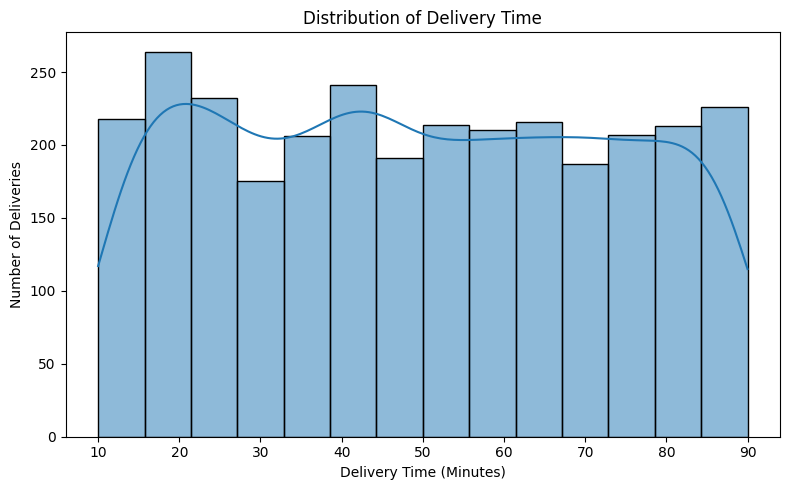

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(data=deliveries, x="delivery_time_minutes", kde=True)
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Deliveries")
plt.tight_layout()
plt.show()

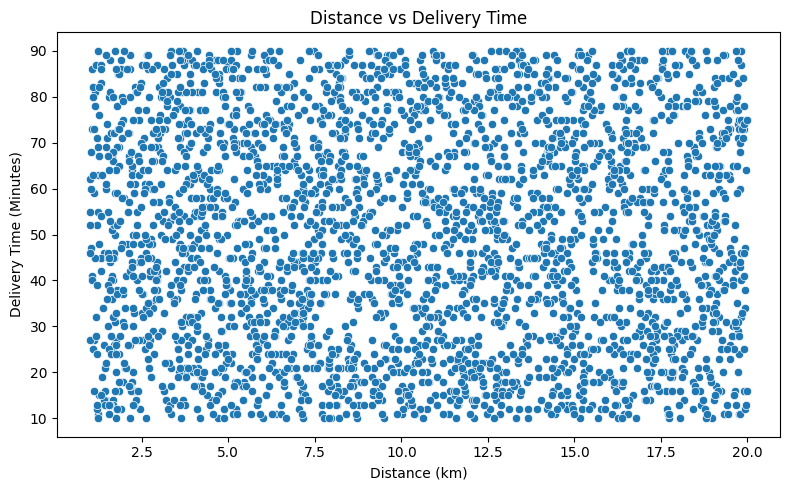

In [5]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=deliveries,
    x="distance_km",
    y="delivery_time_minutes"
)
plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (Minutes)")
plt.tight_layout()
plt.show()

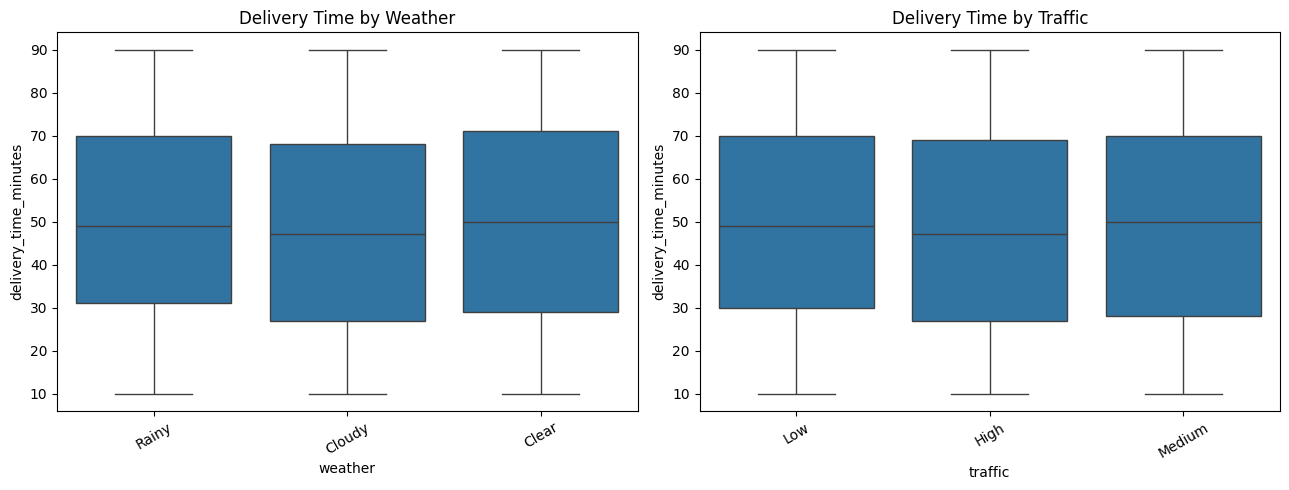

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=deliveries, x="weather", y="delivery_time_minutes", ax=axes[0])
axes[0].set_title("Delivery Time by Weather")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=deliveries, x="traffic", y="delivery_time_minutes", ax=axes[1])
axes[1].set_title("Delivery Time by Traffic")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [7]:
# Check unique weather and traffic categories
print("Weather categories:", deliveries["weather"].unique())
print("\nTraffic categories:", deliveries["traffic"].unique())

# Check numerical distributions
display(deliveries[["distance_km", "delivery_time_minutes"]].describe())

Weather categories: ['Rainy' 'Cloudy' 'Clear']

Traffic categories: ['Low' 'High' 'Medium']


,distance_km,delivery_time_minutes
count,3000.000000,3000.000000
mean,10.343590,49.399667
std,5.444326,23.496311
min,1.000000,10.000000
25%,5.617500,28.000000
50%,10.345000,49.000000
75%,14.920000,70.000000
max,19.990000,90.000000


In [9]:
from sklearn.model_selection import train_test_split

# Select features and target
X = deliveries[["distance_km", "weather", "traffic"]]
y = deliveries["delivery_time_minutes"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (2400, 3)
Testing features: (600, 3)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify numerical and categorical features
numerical_features = ["distance_km"]
categorical_features = ["weather", "traffic"]

# Preprocess numerical and categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Training data shape after encoding:", X_train_processed.shape)
print("Testing data shape after encoding:", X_test_processed.shape)
print("\nEncoded feature names:")
print(preprocessor.get_feature_names_out())

Training data shape after encoding: (2400, 7)
Testing data shape after encoding: (600, 7)

Encoded feature names:
['num__distance_km' 'cat__weather_Clear' 'cat__weather_Cloudy'
 'cat__weather_Rainy' 'cat__traffic_High' 'cat__traffic_Low'
 'cat__traffic_Medium']


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Define the regression models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, random_state=42
    )
}

# Store model evaluation results
results = []
trained_models = {}

for name, model in models.items():
    # Train the model
    model.fit(X_train_processed, y_train)

    # Predict delivery times
    y_pred = model.predict(X_test_processed)

    # Evaluate predictions
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 4)
    })

    trained_models[name] = model

# Display comparison
results_df = pd.DataFrame(results)
display(results_df.sort_values(by="MAE"))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,20.48,23.67,0.0007
2,Gradient Boosting,20.79,24.11,-0.0366
1,Random Forest,22.29,26.84,-0.2841


In [12]:
# Average delivery time by weather
print("Average delivery time by weather:")
display(
    deliveries.groupby("weather")["delivery_time_minutes"]
    .agg(["mean", "median", "count"])
    .round(2)
)

# Average delivery time by traffic
print("\nAverage delivery time by traffic:")
display(
    deliveries.groupby("traffic")["delivery_time_minutes"]
    .agg(["mean", "median", "count"])
    .round(2)
)

# Correlation between distance and delivery time
print("\nCorrelation between distance and delivery time:")
print(
    deliveries["distance_km"].corr(
        deliveries["delivery_time_minutes"]
    ).round(3)
)

Average delivery time by weather:


,mean,median,count
weather,,,
Clear,49.97,50.0,1108
Cloudy,48.01,47.0,968
Rainy,50.17,49.0,924



Average delivery time by traffic:


,mean,median,count
traffic,,,
High,48.60,47.0,1018
Low,50.13,49.0,993
Medium,49.49,50.0,989



Correlation between distance and delivery time:
-0.02


In [13]:
# 1. Average delivery time by weather
print("Average Delivery Time by Weather:")
display(
    deliveries.groupby("weather")["delivery_time_minutes"]
    .agg(["mean", "median", "count"])
    .round(2)
)

# 2. Average delivery time by traffic
print("\nAverage Delivery Time by Traffic:")
display(
    deliveries.groupby("traffic")["delivery_time_minutes"]
    .agg(["mean", "median", "count"])
    .round(2)
)

# 3. Correlation between distance and delivery time
correlation = deliveries["distance_km"].corr(
    deliveries["delivery_time_minutes"]
)
print("\nDistance-Delivery Time Correlation:", round(correlation, 3))

Average Delivery Time by Weather:


,mean,median,count
weather,,,
Clear,49.97,50.0,1108
Cloudy,48.01,47.0,968
Rainy,50.17,49.0,924



Average Delivery Time by Traffic:


,mean,median,count
traffic,,,
High,48.60,47.0,1018
Low,50.13,49.0,993
Medium,49.49,50.0,989



Distance-Delivery Time Correlation: -0.02


In [14]:
# Feature importance from tree-based models

feature_names = preprocessor.get_feature_names_out()

for model_name in ["Random Forest", "Gradient Boosting"]:
    model = trained_models[model_name]

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": model.feature_importances_
    }).sort_values(by="Importance", ascending=False)

    print(f"\nFeature Importance - {model_name}")
    display(importance_df.round(4))


Feature Importance - Random Forest


,Feature,Importance
0,num__distance_km,0.7972
4,cat__traffic_High,0.0387
6,cat__traffic_Medium,0.0386
5,cat__traffic_Low,0.0371
1,cat__weather_Clear,0.0319
3,cat__weather_Rainy,0.0306
2,cat__weather_Cloudy,0.0259



Feature Importance - Gradient Boosting


,Feature,Importance
0,num__distance_km,0.8573
3,cat__weather_Rainy,0.0433
2,cat__weather_Cloudy,0.0313
4,cat__traffic_High,0.0220
5,cat__traffic_Low,0.0196
6,cat__traffic_Medium,0.0161
1,cat__weather_Clear,0.0105


In [15]:
# Compare actual and predicted delivery times

best_model = trained_models["Linear Regression"]

y_pred = best_model.predict(X_test_processed)

comparison_df = pd.DataFrame({
    "Actual Delivery Time": y_test.values,
    "Predicted Delivery Time": np.round(y_pred, 2)
})

comparison_df["Prediction Error"] = (
    comparison_df["Actual Delivery Time"]
    - comparison_df["Predicted Delivery Time"]
).round(2)

display(comparison_df.head(10))

,Actual Delivery Time,Predicted Delivery Time,Prediction Error
0,27,48.88,-21.88
1,28,49.54,-21.54
2,65,48.28,16.72
3,75,47.90,27.10
4,48,48.17,-0.17
5,61,51.30,9.70
6,63,50.15,12.85
7,71,50.53,20.47
8,38,49.43,-11.43
9,55,47.72,7.28


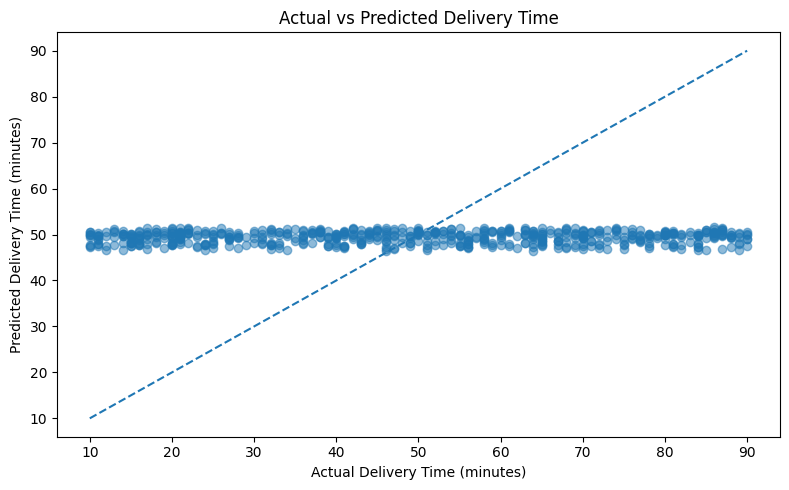

In [16]:
# Actual vs Predicted Delivery Time

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time")
plt.tight_layout()
plt.show()

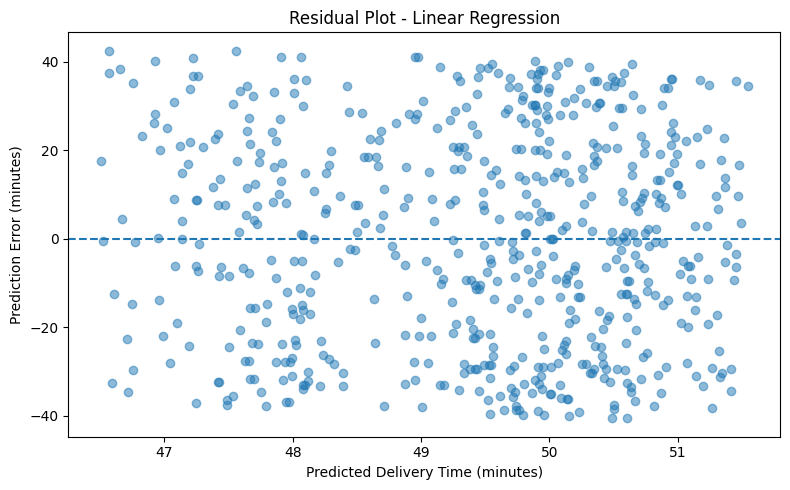

Mean Prediction Error: -0.2
Mean Absolute Error: 20.48
Root Mean Squared Error: 23.67
R2 Score: 0.0007


In [17]:
# Residual Analysis

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Delivery Time (minutes)")
plt.ylabel("Prediction Error (minutes)")
plt.title("Residual Plot - Linear Regression")
plt.tight_layout()
plt.show()

print("Mean Prediction Error:", round(residuals.mean(), 2))
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Root Mean Squared Error:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

In [18]:
import os
import joblib

# Create the models directory if it does not exist
os.makedirs("../models", exist_ok=True)

# Save the best-performing baseline model
joblib.dump(
    trained_models["Linear Regression"],
    "../models/delivery_time_linear_regression.pkl"
)

# Save the fitted preprocessing object
joblib.dump(
    preprocessor,
    "../models/delivery_time_preprocessor.pkl"
)

print("Linear Regression model saved successfully.")
print("Preprocessor saved successfully.")

Linear Regression model saved successfully.
Preprocessor saved successfully.


In [19]:
# Final Model Comparison

results_df = results_df.sort_values(by="MAE").reset_index(drop=True)

print("Final Delivery Time Prediction Model Comparison")
display(results_df)

best_model_name = results_df.loc[0, "Model"]

print("Best Baseline Model:", best_model_name)
print("Lowest MAE:", results_df.loc[0, "MAE"])
print("Best Model R2 Score:", results_df.loc[0, "R2 Score"])

Final Delivery Time Prediction Model Comparison


,Model,MAE,RMSE,R2 Score
0,Linear Regression,20.48,23.67,0.0007
1,Gradient Boosting,20.79,24.11,-0.0366
2,Random Forest,22.29,26.84,-0.2841


Best Baseline Model: Linear Regression
Lowest MAE: 20.48
Best Model R2 Score: 0.0007


In [20]:
# Create output directory and save evaluation results

import os

os.makedirs("../outputs", exist_ok=True)

results_df.to_csv(
    "../outputs/day4_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [21]:
day4_summary = {
    "Task": [
        "Dataset Loading",
        "Data Quality Check",
        "Feature Engineering",
        "Model Training",
        "Model Evaluation",
        "Best Baseline Model",
        "Key Finding",
        "Limitation"
    ],
    "Result": [
        "Loaded 3000 delivery records",
        "No missing values or duplicate rows",
        "Used distance_km, weather and traffic",
        "Trained Linear Regression, Random Forest and Gradient Boosting",
        "Compared MAE, RMSE and R2 Score",
        "Linear Regression",
        "Distance correlation with delivery time is -0.02",
        "Current features provide weak predictive performance"
    ]
}

day4_summary_df = pd.DataFrame(day4_summary)

display(day4_summary_df)

day4_summary_df.to_csv(
    "../outputs/day4_project_summary.csv",
    index=False
)

print("Day 4 project summary saved successfully.")

,Task,Result
0,Dataset Loading,Loaded 3000 delivery records
1,Data Quality Check,No missing values or duplicate rows
2,Feature Engineering,"Used distance_km, weather and traffic"
3,Model Training,"Trained Linear Regression, Random Forest and G..."
4,Model Evaluation,"Compared MAE, RMSE and R2 Score"
5,Best Baseline Model,Linear Regression
6,Key Finding,Distance correlation with delivery time is -0.02
7,Limitation,Current features provide weak predictive perfo...


Day 4 project summary saved successfully.


In [22]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

regularized_models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000)
}

regularized_results = []

for name, model in regularized_models.items():
    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    regularized_results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 4)
    })

    trained_models[name] = model

regularized_results_df = pd.DataFrame(regularized_results)

display(regularized_results_df)

,Model,MAE,RMSE,R2 Score
0,Ridge Regression,20.48,23.67,0.0007
1,Lasso Regression,20.49,23.68,0.0001


In [23]:
all_results_df = pd.concat(
    [results_df, regularized_results_df],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    by="MAE"
).reset_index(drop=True)

display(all_results_df)

all_results_df.to_csv(
    "../outputs/day4_model_comparison.csv",
    index=False
)

print("Best model based on MAE:", all_results_df.loc[0, "Model"])

,Model,MAE,RMSE,R2 Score
0,Linear Regression,20.48,23.67,0.0007
1,Ridge Regression,20.48,23.67,0.0007
2,Lasso Regression,20.49,23.68,0.0001
3,Gradient Boosting,20.79,24.11,-0.0366
4,Random Forest,22.29,26.84,-0.2841


Best model based on MAE: Linear Regression


In [24]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.base import clone

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, model in trained_models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", clone(model))
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    cv_results.append({
        "Model": name,
        "Mean CV MAE": round(-scores.mean(), 2),
        "CV MAE Std": round(scores.std(), 2)
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.sort_values(by="Mean CV MAE"))

cv_results_df.to_csv(
    "../outputs/day4_cross_validation_results.csv",
    index=False
)

,Model,Mean CV MAE,CV MAE Std
4,Lasso Regression,20.37,0.26
0,Linear Regression,20.38,0.27
3,Ridge Regression,20.38,0.27
2,Gradient Boosting,20.59,0.25
1,Random Forest,22.04,0.30


In [25]:
# Outlier Analysis using IQR

Q1 = deliveries["delivery_time_minutes"].quantile(0.25)
Q3 = deliveries["delivery_time_minutes"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = deliveries[
    (deliveries["delivery_time_minutes"] < lower_bound) |
    (deliveries["delivery_time_minutes"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Potential Outliers:", len(outliers))

display(outliers.head(10))

Q1: 28.0
Q3: 70.0
IQR: 42.0
Lower Bound: -35.0
Upper Bound: 133.0
Number of Potential Outliers: 0


,delivery_id,order_id,driver_id,distance_km,delivery_time_minutes,weather,traffic


In [26]:
# Identify observations with the largest prediction errors

best_model = trained_models["Linear Regression"]

y_pred = best_model.predict(X_test_processed)

residual_analysis = pd.DataFrame({
    "Actual_Delivery_Time": y_test.to_numpy(),
    "Predicted_Delivery_Time": y_pred,
    "Absolute_Error": np.abs(y_test.to_numpy() - y_pred)
}, index=y_test.index)

residual_analysis = residual_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
)

print("10 Observations with the Largest Prediction Errors:")
display(residual_analysis.head(10))

10 Observations with the Largest Prediction Errors:


,Actual_Delivery_Time,Predicted_Delivery_Time,Absolute_Error
1904,90,47.559876,42.440124
859,89,46.567713,42.432287
2523,89,47.909202,41.090798
521,90,48.954973,41.045027
926,90,48.973645,41.026355
729,89,48.066150,40.933850
2453,88,47.220579,40.779421
1624,10,50.601669,40.601669
2890,10,50.487740,40.487740
102,10,50.152353,40.152353


In [27]:
# Feature Importance from Random Forest

feature_names = preprocessor.get_feature_names_out()

rf_model = trained_models["Random Forest"]

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df)

feature_importance_df.to_csv(
    "../outputs/day4_feature_importance.csv",
    index=False
)

,Feature,Importance
0,num__distance_km,0.797209
4,cat__traffic_High,0.038746
6,cat__traffic_Medium,0.038617
5,cat__traffic_Low,0.037078
1,cat__weather_Clear,0.031902
3,cat__weather_Rainy,0.030562
2,cat__weather_Cloudy,0.025887


In [28]:
import os

required_files = [
    "../outputs/day4_model_comparison.csv",
    "../outputs/day4_cross_validation_results.csv",
    "../outputs/day4_feature_importance.csv",
    "../models/delivery_time_linear_regression.pkl",
    "../models/delivery_time_preprocessor.pkl"
]

for file_path in required_files:
    print(
        f"{'FOUND' if os.path.exists(file_path) else 'MISSING'}: "
        f"{file_path}"
    )

FOUND: ../outputs/day4_model_comparison.csv
FOUND: ../outputs/day4_cross_validation_results.csv
FOUND: ../outputs/day4_feature_importance.csv
FOUND: ../models/delivery_time_linear_regression.pkl
FOUND: ../models/delivery_time_preprocessor.pkl


In [29]:
best_result = all_results_df.loc[all_results_df["MAE"].idxmin()]

print("Recommended Model:", best_result["Model"])
print("MAE:", best_result["MAE"])
print("RMSE:", best_result["RMSE"])
print("R2 Score:", best_result["R2 Score"])

Recommended Model: Linear Regression
MAE: 20.48
RMSE: 23.67
R2 Score: 0.0007


In [30]:
import os
import joblib

best_model_name = best_result["Model"]
best_model = trained_models[best_model_name]

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/day4_best_delivery_time_model.pkl"
)

joblib.dump(
    preprocessor,
    "../models/day4_delivery_time_preprocessor.pkl"
)

print("Selected model:", best_model_name)
print("Final model and preprocessor saved successfully.")

Selected model: Linear Regression
Final model and preprocessor saved successfully.


In [31]:
recommendation = pd.DataFrame([{
    "Target": "delivery_time_minutes",
    "Recommended_Model": best_model_name,
    "MAE": best_result["MAE"],
    "RMSE": best_result["RMSE"],
    "R2_Score": best_result["R2 Score"],
    "Business_Recommendation": (
        "Improve predictive performance by evaluating additional relevant "
        "features before using the model for operational decisions."
    )
}])

display(recommendation)

recommendation.to_csv(
    "../outputs/day4_final_recommendation.csv",
    index=False
)

print("Final recommendation saved successfully.")

,Target,Recommended_Model,MAE,RMSE,R2_Score,Business_Recommendation
0,delivery_time_minutes,Linear Regression,20.48,23.67,0.0007,Improve predictive performance by evaluating a...


Final recommendation saved successfully.
